# Exploratory Data Analysis and Data Quality

Exploratory data analysis (EDA) is the systematic first look at a dataset before any model is built. Its purpose is twofold: to understand the structure of the data – distributions, relationships, patterns over time – and to find problems – gaps, outliers, implausible values, inconsistencies. In engineering, a large share of failed data science projects can be traced back to data problems that a careful EDA would have revealed.

The statistician John Tukey, who coined the term, put it this way: EDA is detective work. We look for clues without knowing in advance what we will find. The tools are simple – summary statistics and plots – but using them well requires domain knowledge.

In terms of the CRISP-DM process from Chapter 1, EDA is the core of phase 2, *data understanding*. The original CRISP-DM model names four tasks for this phase, and this chapter follows them: **collect** the data (@sec-raw-data), **describe** them (@sec-distributions), **explore** them (@sec-time-patterns) and **verify their quality** (@sec-outliers and @sec-missing-data). The findings determine what happens in phase 3, *data preparation* – which outliers to keep, how to fill gaps, which sensors to drop. And they often lead back to phase 1: can the question be answered with these data at all? The scenario of this chapter is exactly such a decision.

![Where this chapter belongs in the CRISP-DM process: data understanding and data preparation.](images/crisp-ch02.png){width=45% fig-align="center"}

::: {.scenario}
**Scenario: go or no-go for a failure prediction project**

A semiconductor fab wants to predict failed production runs from its process data. A project budget for one year has been requested, and the fab manager asks you for a quick assessment before signing: "We have almost 600 sensors and more than 1,500 runs – that must be enough, right?" You have one week to look at the data.

**Your decision:** Recommend starting the project now, or first investing in better data?
:::

**Learning goals.** After this chapter you can

- read a raw sensor file correctly (separator, missing value code, time stamps, time zone),
- describe distributions numerically (location, spread, shape) and visually (histogram, box plot),
- explore a sensor dataset over time with rolling means, resampling and heatmaps,
- detect outliers with the IQR rule and robust z-scores and decide how to treat them,
- characterise missing data (MCAR, MAR, MNAR) and choose an appropriate treatment,
- judge whether a dataset is fit for the intended analysis.

**Datasets in this chapter**

- [DWD Climate Data Center – hourly station data](https://opendata.dwd.de/climate_environment/CDC/)
- [Appliances Energy Prediction (UCI)](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction)
- [SECOM (UCI)](https://archive.ics.uci.edu/dataset/179/secom)

## Reading raw data {#sec-raw-data}

Before data can be described, they have to be read – and read correctly. Real measurement data rarely come as a ready-made table: they arrive as text files with their own separators, codes for missing values and time formats. This section shows two typical cases – a raw file from a weather service and a sensor dataset with an unusual time format. First, the usual setup:

In [1]:
#| code-fold: false
# Setup (as in every chapter): install packages that are not pre-installed in
# Google Colab or Anaconda, then import the standard data stack.
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:        # package not found?
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")                     # common style for all plots

### Live coding: a raw weather file

In Chapter 1, the trading desk of the power plant needed temperature data to commit its output – and weather services deliver such data as raw files. As an example, we load hourly air temperature and humidity from the German Weather Service (DWD), station Trier-Petrisberg (station ID 05100). The power plant of Chapter 1 is not located in Trier, and the file contains measured values, not forecasts – but the steps are the same for any weather service and any raw sensor file.

The DWD provides the data as a zip archive containing a semicolon-separated text file plus metadata files. Missing values are coded as `-999`. This is typical for raw data: we have to know the file structure, the separator, the missing value code and the time format before we can use the data. All of this is documented: the DWD describes the dataset in a [dataset description](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/hourly/air_temperature/DESCRIPTION_obsgermany_climate_hourly_air_temperature_en.pdf) (columns, formats, the products `recent` and `historical`), and every archive contains metadata files with further details, e.g. on missing values. Reading this documentation is part of the task *collect* in CRISP-DM phase 2. When reading the file, we replace the code `-999` by `NaN` ("not a number"), the marker that pandas uses for a missing value. Otherwise, `-999` would count as a real temperature of −999 °C and distort every mean.

Because the file is only needed once, we use a small helper function `download()`: it fetches a file from the internet on the first run and keeps a copy in the folder `data`; every later run reads this copy.

In [2]:
#| code-fold: false
from pathlib import Path
import requests

DATA = Path("data")
DATA.mkdir(exist_ok=True)                         # create the folder ./data if it does not exist

def download(url, fname=None):
    """Download a file once and cache it in ./data."""
    if fname is None:                             # no file name given:
        fname = url.split("/")[-1]                # use the last part of the URL
    path = DATA / fname                           # "/" joins folder and file name
    if not path.exists():                         # download only if not cached yet
        r = requests.get(url, timeout=120)        # give up after 120 s without response
        r.raise_for_status()                      # stop with an error if the download failed
        path.write_bytes(r.content)               # open, write and close the file in one step
    return path

In [3]:
#| code-fold: false
import zipfile

# The URL is long; we build it from three parts with "+":
server  = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
product = "climate/hourly/air_temperature/recent/"   # hourly air temperature, recent data
fname   = "stundenwerte_TU_05100_akt.zip"           # 05100 = station ID of Trier-Petrisberg
url = server + product + fname

with zipfile.ZipFile(download(url)) as z:       # open the archive (closed after the block)
    print(z.namelist())                         # what is inside?
    # The data file is the one whose name starts with "produkt". Its full name contains
    # the dates of the measurement period and changes daily, so we search for it:
    for n in z.namelist():
        if n.startswith("produkt"):
            name = n
            break                               # found: stop searching
    dwd = pd.read_csv(z.open(name),             # read the file directly from the archive
                      sep=";",                  # columns are separated by semicolons
                      na_values=[-999],         # replace the code -999 by NaN ("missing")
                      skipinitialspace=True)    # ignore blanks after each separator

dwd.columns = dwd.columns.str.strip()           # remove blanks around the column names
dwd.head()

['Metadaten_Stationsname_Betreibername_05100.html', 'Metadaten_Stationsname_Betreibername_05100.txt', 'Metadaten_Parameter_tu_stunde_05100.html', 'Metadaten_Parameter_tu_stunde_05100.txt', 'Metadaten_Geraete_Lufttemperatur_05100.html', 'Metadaten_Geraete_Lufttemperatur_05100.txt', 'Metadaten_Geraete_Rel_Feuchte_05100.html', 'Metadaten_Geraete_Rel_Feuchte_05100.txt', 'Metadaten_Geographie_05100.txt', 'Metadaten_Fehldaten_05100_20250411_20261012.html', 'Metadaten_Fehldaten_05100_20250411_20261012.txt', 'Metadaten_Fehlwerte_05100_20250411_20261012.txt', 'produkt_tu_stunde_20250411_20261012_05100.txt']


,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,eor
0,5100,2025041100,3,4.9,83.0,eor
1,5100,2025041101,3,4.5,85.0,eor
2,5100,2025041102,3,3.6,88.0,eor
3,5100,2025041103,3,2.8,91.0,eor
4,5100,2025041104,3,1.8,92.0,eor


The raw table has cryptic column names (`TT_TU` = air temperature in °C, `RF_TU` = relative humidity in %, `QN_9` = quality level). `STATIONS_ID` and `QN_9` are stored as numbers but are codes, i.e. categorical variables (Chapter 1). The time stamp `MESS_DATUM` is an integer such as `2025041113` (year, month, day, hour). We convert the time stamp into a proper `datetime`, use it as the index and give the columns meaningful names. The format codes such as `%Y` for the year are listed in @sec-python-reference.

In [4]:
#| code-fold: false
# MESS_DATUM is an integer such as 2025041113 (year, month, day, hour):
# convert it to text and parse it with the matching format into a real time stamp.
# Format codes: %Y = year (4 digits); %m = month, %d = day, %H = hour (2 digits each).
dwd["time"] = pd.to_datetime(dwd["MESS_DATUM"].astype(str), format="%Y%m%d%H")
weather = (dwd.set_index("time")[["TT_TU", "RF_TU"]]           # time as index, two columns
              .rename(columns={"TT_TU": "temp_C", "RF_TU": "rel_humidity_pct"}))
print(weather.isna().sum())     # number of missing values per column
weather.tail()                  # last five rows

temp_C              19
rel_humidity_pct    19
dtype: int64


,temp_C,rel_humidity_pct
time,,
2026-10-12 19:00:00,12.3,71.0
2026-10-12 20:00:00,11.4,74.0
2026-10-12 21:00:00,10.9,76.0
2026-10-12 22:00:00,9.9,82.0
2026-10-12 23:00:00,9.8,78.0


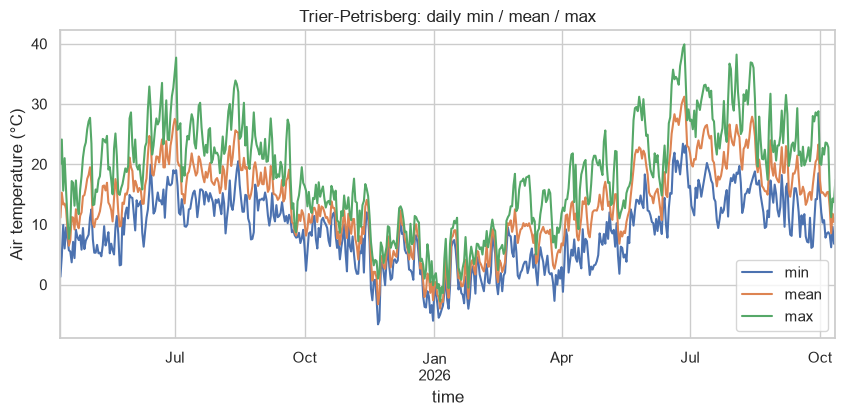

In [5]:
# resample("D") groups the hourly values by day; agg computes three statistics per day.
daily = weather["temp_C"].resample("D").agg(["min", "mean", "max"])
ax = daily.plot(figsize=(10, 4))                 # one line per column: min, mean, max
ax.set(ylabel="Air temperature (°C)", title="Trier-Petrisberg: daily min / mean / max")
plt.show()

**Discussion.** With a time index, pandas offers powerful operations: `resample("D")` aggregates hourly values to days, and we can compute several statistics at once. The plot shows the seasonal cycle and the day-to-day weather variability. Note the time zone: the DWD files of this product use UTC. When you combine such data with local production data, time zones and daylight saving time must be handled explicitly – a common source of one-hour shifts.

The output above also reports a few missing hours – the former `-999` codes, now `NaN`. Why they are missing is documented in the metadata file `Metadaten_Fehldaten_…` in the archive. Reading it is the first step before choosing a treatment (@sec-missing-data).

::: {.callout-tip}
## Engineering practice: data from databases
In companies, engineering data often come from databases rather than files – process data from a historian, quality and order data from a manufacturing execution system. They are read with SQL: a few commands such as `SELECT`, `WHERE`, `GROUP BY` and `JOIN` cover most needs, and `pd.read_sql` loads the result directly into pandas. The questions of this section remain the same: units, missing values (in SQL: `NULL`) and time zones. @sec-databases gives a short introduction.
:::

### Live coding: the energy data of a house

Our second dataset accompanies us through the next three sections. It was recorded in a low-energy house in Belgium. A wireless sensor network measured temperature and humidity in nine rooms every 10 minutes for about 4.5 months; the electricity consumption of the appliances was logged by an energy meter, and outdoor weather was taken from a nearby airport. Key columns:

| Column | Meaning | Unit |
| --- | --- | --- |
| `Appliances` | energy use of appliances in the 10-minute interval | Wh |
| `lights` | energy use of light fixtures | Wh |
| `T1` … `T9`, `RH_1` … `RH_9` | temperature and relative humidity in the rooms | °C, % |
| `T_out`, `RH_out`, `Windspeed`, … | outdoor weather | various |
| `rv1`, `rv2` | random variables, added deliberately by the authors | – |

The two random variables are a nice feature of this dataset: a sound analysis should find that they carry no information.

In [6]:
#| code-fold: true
# Helper: parse time stamps with an explicit format. Several common formats are tried one
# after the other; a format is accepted only if it parses *all* time stamps.
def parse_timestamps(s, formats=("%Y-%m-%d %H:%M:%S", "%Y-%m-%d%H:%M:%S", "%Y-%m-%d %H:%M", "%d-%m-%Y %H:%M:%S",
                                 "%d-%m-%Y %H:%M", "%d/%m/%Y %H:%M", "%m/%d/%Y %H:%M",
                                 "%d.%m.%Y %H:%M")):
    for fmt in formats:
        t = pd.to_datetime(s, format=fmt, errors="coerce")   # errors="coerce": NaT instead of
                                                              # an error if a string does not fit
        if t.notna().all():                                   # this format fits every time stamp
            print("Time stamp format:", fmt)
            return t
    # no format fits: show some of the problematic strings in the error message
    bad = s[pd.to_datetime(s, format="mixed", errors="coerce").isna()]
    raise ValueError(f"Unknown time stamp format, e.g. {bad.head(3).tolist() or s.head(3).tolist()}")

In [7]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

appl = fetch_ucirepo(id=374)                       # Appliances Energy Prediction (UCI)
energy = appl.data.original.copy()                 # whole table incl. time, as a copy

raw = energy["date"].astype(str).str.strip()       # look at the raw time stamps first ...
print("Raw time stamps:", raw.head(3).tolist())    # first three, as a plain list
energy["date"] = parse_timestamps(raw)             # ... then parse them with an explicit format
energy = energy.set_index("date").sort_index()     # time as index, in chronological order

# rows and columns, first and last time stamp:
print(energy.shape, energy.index.min(), "to", energy.index.max())
# isna() gives True where a value is missing; True counts as 1, so sum() counts
# the missing values per column, and the second sum() adds up all columns:
print("Missing values:", energy.isna().sum().sum())
# Regular grid: is every time step exactly 10 minutes?
steps = energy.index.to_series().diff().dropna()   # time between consecutive rows
print("Regular 10-min grid:", (steps == pd.Timedelta("10min")).all())

Raw time stamps: ['2016-01-1117:00:00', '2016-01-1117:10:00', '2016-01-1117:20:00']
Time stamp format: %Y-%m-%d%H:%M:%S
(19735, 28) 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Missing values: 0
Regular 10-min grid: True


::: {.callout-warning}
## Pitfall: letting the software guess date formats
Is `03/04/2016` the 3rd of April or the 4th of March? If you let pandas guess, it may parse some time stamps one way and others the other way – or fail on a single unusual entry. Always look at the raw strings and give the format explicitly. Because the measurement period contains days after the 12th, only the correct order of day and month can parse *all* time stamps – the helper `parse_timestamps` (folded above) uses exactly this check.
:::

A real-world surprise: in the version of this dataset served by the UCI repository, date and time are glued together without a space (`2016-01-1117:00:00` for 11 January 2016, 17:00). pandas cannot guess this format – but the explicit format `%Y-%m-%d%H:%M:%S` reads it without problems.

Checking that the time index is regular is a quick but important test. Gaps in the time grid are "hidden" missing values: `df.isna()` does not see them because the rows do not exist at all.

::: {.callout-tip}
## Good practice: downloading and reading raw files
1. **Keep the raw file untouched.** Never correct values by hand in the file. Every step from the raw file to the clean table is code – so anyone can repeat it, including you next semester.
2. **Download once, keep a copy** – like the helper `download()`. Check that the download succeeded (`raise_for_status()`); otherwise an error page may be stored as "data".
3. **Note source and version:** URL, download date, version. Many sources are updated: the DWD product `recent` covers roughly the last 500 days and changes daily, so the same code can give slightly different results next month.
4. **Read the documentation first:** separator, decimal mark, missing value code, units, time format and time zone.
5. **State everything explicitly** instead of letting pandas guess: `sep=";"`, `decimal=","` (numbers with a decimal comma, common in German files), `na_values=[-999]`, `format=` for time stamps.
6. **Check right after reading:** `df.head()`, `df.info()`, `df.describe()`. A numeric column of type `object` contains at least one text entry; a table with only one column or unexpectedly many missing values points to a wrong separator or code.
:::

## Describing distributions {#sec-distributions}

Which description fits a single variable depends on its type (Chapter 1):

- A **categorical** variable is described by the **frequencies** of its categories – counts or shares – and shown in a bar chart. The most frequent category is called the **mode**. For an *ordinal* variable, the median is meaningful as well (quality class M lies in the middle), the mean is not.
- A **numeric** variable is described by its **location** (where are the values?), its **spread** (how much do they vary?) and its **shape** (symmetric, skewed, multimodal?).

Engineering data are mostly numeric, and so is the rest of this section. A categorical example – the pass/fail label of this chapter's scenario – follows in @sec-missing-data.

::: {.callout-note}
## Definition: Location and spread
For numeric observations $x_1, \dots, x_n$:

- **Mean** $\bar x = \frac{1}{n}\sum_i x_i$ and **median** (the middle value of the sorted data).
- **Sample standard deviation** $s = \sqrt{\frac{1}{n-1}\sum_i (x_i - \bar x)^2}$.
- **Quartiles** $Q_1$, $Q_3$ (25 % and 75 % quantiles) and the **interquartile range** $\text{IQR} = Q_3 - Q_1$.
- **Median absolute deviation:** with the median $\tilde x = \operatorname{median}(x_1, \dots, x_n)$,
  $$\text{MAD} = \operatorname{median}\big(|x_1 - \tilde x|, \dots, |x_n - \tilde x|\big),$$
  i.e. the median of the absolute deviations from the median.
:::

Mean and standard deviation are sensitive to extreme values: a single wrong reading of $10^6$ can dominate both. Median, IQR and MAD are **robust**: they barely change if a few values are wrong. For engineering data, where sensor glitches are common, it pays to look at both and compare them.

::: {.callout-tip}
## Which plot for which question?
- *Frequencies of a categorical variable:* bar chart – sorted by frequency, or in the natural order of an ordinal variable.
- *Distribution of a numeric variable:* histogram (shape) or box plot (compact, good for comparing groups).
- *Relationship between two variables:* scatter plot; with many points use transparency or hexbin plots.
- *Development over time:* line plot, possibly with a rolling mean.
- *Patterns over two time scales* (hour of day × weekday): heatmap.
- *Many variables at once:* correlation heatmap, pair plot of a subset.
:::

### Live coding: appliance energy use

The target variable of the energy dataset is the energy use of the appliances. Histogram and box plot show its distribution:

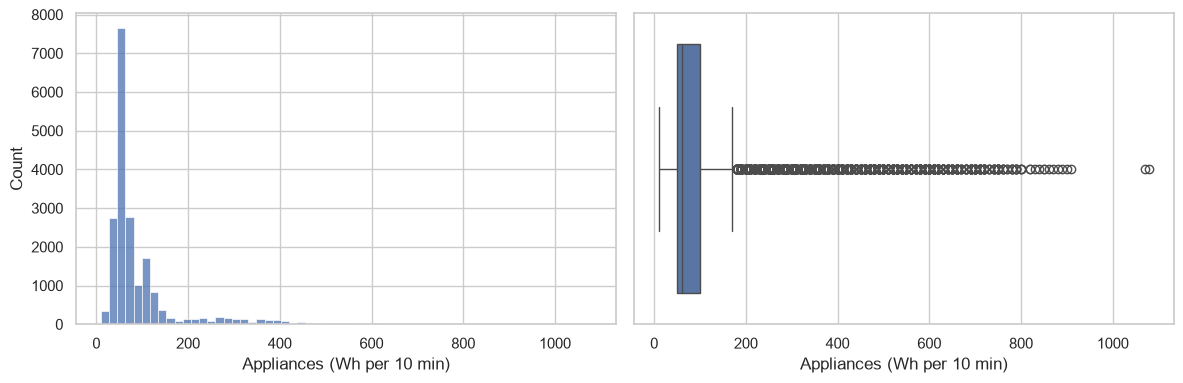

count    19735.0
mean        97.7
std        102.5
min         10.0
25%         50.0
50%         60.0
75%        100.0
max       1080.0
Name: Appliances, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))         # two plots side by side
sns.histplot(energy["Appliances"], bins=60, ax=axes[0])  # histogram with 60 bins (left)
axes[0].set(xlabel="Appliances (Wh per 10 min)")
sns.boxplot(x=energy["Appliances"], ax=axes[1])          # box plot (right); x= draws it horizontally
axes[1].set(xlabel="Appliances (Wh per 10 min)")
plt.tight_layout(); plt.show()                           # tight_layout: avoid overlapping labels
energy["Appliances"].describe().round(1)                 # the same distribution in numbers

**Discussion.** The distribution is strongly **right-skewed**: most of the time the consumption is low (base load from fridge, standby), but occasionally it rises sharply (cooking, washing machine). Consequently, the mean is clearly larger than the median, and the box plot flags many points as "outliers" (@sec-outliers). Here these are not measurement errors but real usage events – deleting them would remove the most interesting part of the data.

For skewed, positive quantities a **log transformation** often helps: it makes the distribution more symmetric and turns multiplicative effects into additive ones.

## Patterns over time {#sec-time-patterns}

Engineering data are mostly time series. Besides the distribution of each variable, its development over time matters: trends, cycles, sudden steps. Two tools help to see them in noisy data: a **rolling mean** smooths short-term fluctuations, and **resampling** aggregates the values to a coarser time grid, e.g. from 10 minutes to hours.

### Live coding: daily and weekly profiles

First the whole measurement period: the 10-minute values of the appliance energy use with a 24-hour rolling mean, and the indoor and outdoor temperature as hourly means:

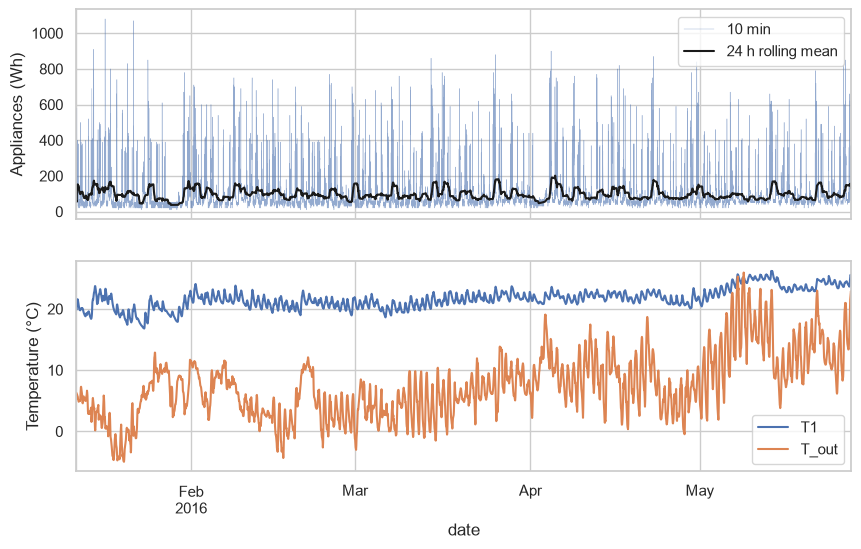

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)   # two plots, one time axis
# top: 10-minute values (thin, transparent line) and their 24-hour rolling mean
energy["Appliances"].plot(ax=axes[0], lw=0.3, alpha=0.6, label="10 min")
energy["Appliances"].rolling("1D").mean().plot(ax=axes[0], color="k", label="24 h rolling mean")
axes[0].set(ylabel="Appliances (Wh)"); axes[0].legend()
# bottom: indoor and outdoor temperature, resampled from 10 minutes to hourly means
energy[["T1", "T_out"]].resample("h").mean().plot(ax=axes[1])
axes[1].set(ylabel="Temperature (°C)")
plt.show()

The rolling mean reveals the level of consumption over time. Indoor temperature `T1` is much more stable than the outdoor temperature – as expected for a well-insulated building.

Consumption depends on human behaviour, so we expect patterns over the hour of the day and the day of the week. A heatmap shows both at once:

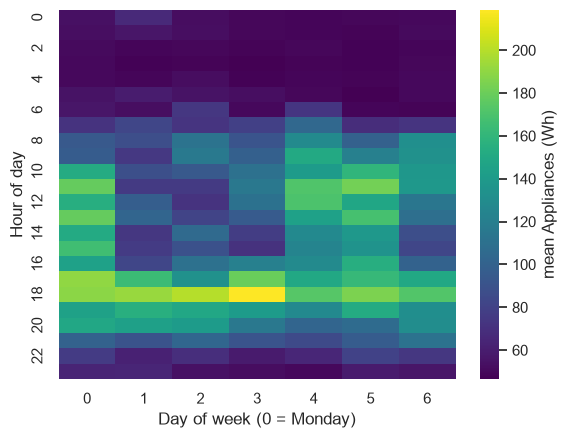

In [10]:
# Mean consumption for every combination of weekday (0 = Monday) and hour of day.
# unstack(0) turns the weekday into columns: a table with 24 rows (hours) and 7 columns.
profile = energy.groupby([energy.index.dayofweek, energy.index.hour])["Appliances"].mean().unstack(0)
sns.heatmap(profile, cmap="viridis",                      # colour = mean consumption
            cbar_kws={"label": "mean Appliances (Wh)"})   # label of the colour bar
plt.xlabel("Day of week (0 = Monday)"); plt.ylabel("Hour of day")
plt.show()

**Discussion.** Low consumption at night, a rise in the morning and a peak in the evening hours – a typical residential profile. Such patterns are important for later modelling: hour of day and weekday are strong features for forecasting (Chapter 11).

## Data quality and outliers {#sec-outliers}

Measured data pass through a long chain – sensor, signal conditioning, A/D conversion, data logger, database, export – and every link can introduce errors. Typical problems:

| Problem | Typical cause | How to detect |
| --- | --- | --- |
| Missing values | sensor dropout, logging gap, value not measured for every product | `df.isna()`, gaps in the time index (@sec-missing-data) |
| Outliers | real rare event *or* measurement error | box plot, IQR rule, robust z-score |
| Implausible values | sensor fault, wrong scaling | physical limits (e.g. humidity > 100 %) |
| Frozen values | sensor stuck, communication lost | long runs of identical values |
| Coarse resolution | A/D converter or logger rounds values (e.g. to 0.1 K) | many identical values, gaps in the histogram |
| Wrong units / time stamps | °C vs. K, local time vs. UTC | domain knowledge, comparison of sources (@sec-raw-data) |
| Drift and offsets | sensor ageing, recalibration | trends, steps in the time series |

Two of these problems need more than a quick check: outliers, treated in this section, and missing values (@sec-missing-data).

::: {.callout-note}
## Definition: Outlier rules
- **IQR rule (Tukey):** a value is flagged if it lies below $Q_1 - 1.5\,\text{IQR}$ or above $Q_3 + 1.5\,\text{IQR}$. These are the whiskers of the box plot.
- **Robust z-score:** $z_i = \dfrac{x_i - \tilde x}{1.4826 \cdot \text{MAD}}$, flag if $|z_i| > 3.5$, where $\tilde x$ is the median. The factor 1.4826 makes MAD comparable to the standard deviation for normally distributed data.
:::

The ordinary z-score $(x_i - \bar x)/s$ is less suitable for outlier detection: the outliers themselves inflate $\bar x$ and $s$ and can hide each other (*masking*).

::: {.callout-warning}
## Pitfall: deleting "outliers" automatically
An outlier is a value that is unusual *with respect to a model* of the data – it is not automatically an error. The rare high current peaks of a motor may be exactly the events that announce a failure. Never delete data before you understand why they are extreme, and always document what you removed.
:::

### Live coding: outliers in the energy data

We apply both rules to the appliance energy use and to three variables with roughly symmetric distributions:

In [11]:
#| code-fold: false
def iqr_outliers(x, k=1.5):
    """IQR rule: True for values more than k * IQR below Q1 or above Q3."""
    q1, q3 = x.quantile([0.25, 0.75])
    return (x < q1 - k * (q3 - q1)) | (x > q3 + k * (q3 - q1))

def robust_z(x):
    """Robust z-score: distance from the median in units of 1.4826 * MAD."""
    mad = (x - x.median()).abs().median()            # median absolute deviation
    return (x - x.median()) / (1.4826 * mad)

for col in ["Appliances", "T1", "T_out", "RH_1"]:
    x = energy[col]
    share_iqr = iqr_outliers(x).mean()               # mean of True/False = share of flagged values
    share_z = (robust_z(x).abs() > 3.5).mean()
    print(f"{col:11s} IQR rule: {share_iqr:6.1%}   |robust z| > 3.5: {share_z:6.1%}")

Appliances  IQR rule:  10.8%   |robust z| > 3.5:  11.2%
T1          IQR rule:   2.6%   |robust z| > 3.5:   0.2%
T_out       IQR rule:   2.2%   |robust z| > 3.5:   0.3%
RH_1        IQR rule:   0.7%   |robust z| > 3.5:   0.2%


For the room temperature and humidity, very few values are flagged; for `Appliances`, many. This confirms that a fixed rule cannot decide alone: the flags tell us where to *look*, the engineer decides what the values mean.

## Missing data {#sec-missing-data}

Almost every real dataset has gaps. How to treat them depends less on *how many* values are missing than on *why* they are missing. Statisticians distinguish three mechanisms. Because the names are notoriously confusing, we explain them with one running example.

**Example: a hardening furnace.** A thermocouple measures the furnace temperature once per minute; the target is about 850 °C. The actual temperature depends on the load: a fully loaded furnace runs hotter than a nearly empty one. The load is logged reliably by the control system. Now suppose that some temperature values are missing. Three different reasons are possible:

1. **The radio link drops messages at random.** About 10 % of the readings are lost, regardless of load, temperature or time of day. Whether a value is missing has nothing to do with the process.
2. **The logger runs in an energy-saving mode at low load.** When the furnace is nearly empty, only every fifth reading is stored. Missing values are therefore much more frequent at low load – and since low load means lower temperatures, the missing values tend to be the lower ones. But the reason for the gap (low load) is itself recorded in the data.
3. **The amplifier saturates above 900 °C.** Whenever the furnace gets too hot, the measurement fails and nothing is stored. The values are missing *because* they are high. The load gives a hint – very hot readings occur at high load – but it cannot tell us which readings actually exceeded 900 °C.

::: {.callout-note}
## Definition: Missing data mechanisms
Let $R$ indicate whether a value is missing.

- **MCAR** (missing completely at random): $R$ does not depend on any variable, observed or unobserved. *Case 1 – random radio losses.*
- **MAR** (missing at random): $R$ depends only on **observed** variables. Once we know those (here: the load), the missingness tells us nothing more about the missing value: at a given load, the missing temperatures do not differ from the recorded ones. *Case 2 – energy-saving mode at low load.*
- **MNAR** (missing not at random): $R$ depends on the **missing value itself** (or on other unobserved quantities), even after accounting for everything observed. *Case 3 – saturation at high temperatures.*
:::

::: {.callout-warning}
## Pitfall: "missing at random" is not random
The name MAR is misleading: in case 2 the values are *not* missing randomly – low temperatures are missing much more often. "At random" only means "random once we take the observed variables into account". Do not read MAR as "harmless".
:::

What the mechanism means in practice:

| Mechanism | Mean of the remaining values | What helps |
| --- | --- | --- |
| MCAR | unbiased – we just have fewer values | deleting incomplete rows is acceptable – only the sample gets smaller; filling gaps with the mean or median keeps the mean unbiased, but makes the spread look too small |
| MAR | **biased** (case 2: too high, because low values are missing) | use the observed variable that explains the gaps – e.g. impute temperature from load with a regression, or average per load level |
| MNAR | **biased** (case 3: too low, because high values are missing) | the data alone cannot fix it; we need knowledge of the mechanism (e.g. "missing means > 900 °C", see @sec-mnar-extension) or a better sensor |

The first live coding below simulates the furnace and shows these effects in numbers. Common strategies in practice:

- drop variables with a very high share of missing values,
- drop rows if few are affected and the mechanism is plausibly MCAR,
- impute with the median (simple, but it shrinks the spread and ignores *why* values are missing) or with a model that uses the variables explaining the gaps (MAR),
- for time series: interpolate short gaps, but not long ones,
- add an indicator variable "value was missing" – missingness itself can be informative,
- above all: find out *why* the values are missing – ask the people who run the process.

### Live coding: how missing values bias a mean

We simulate the furnace from the example above: 10,000 readings, load between 0 and 1, temperature rising with load. Then we delete values according to the three mechanisms and compare four ways of dealing with the gaps: dropping them, filling them with the mean or the median of the remaining values, and filling them from the load with a straight-line regression fitted on the complete rows. For each, we check two numbers against the truth: the mean and the standard deviation.

In [12]:
#| code-fold: false
# --- 1. Simulate the "true" furnace data ------------------------------------------
# A random number generator with a fixed start value (seed = 0): every run produces
# the same random numbers, so the results in the script are reproducible.
# default_rng is NumPy's recommended way to create such a generator.
rng = np.random.default_rng(0)

n = 10_000                                   # number of readings (_ only for readability)
load = rng.uniform(0, 1, n)                  # load between 0 (empty) and 1 (full);
                                             # always recorded – no gaps
noise = rng.normal(0, 15, n)                 # random scatter, standard deviation 15 K
temp = 820 + 80 * load + noise               # true temperature: 820 °C empty, 900 °C full

# --- 2. Delete values according to the three mechanisms ---------------------------
# Each mask is an array of n truth values: True means "this reading is missing".
# rng.random(n) draws n numbers between 0 and 1; "< p" is True with probability p.
missing = {
    "MCAR": rng.random(n) < 0.10,               # random radio losses: always 10 %
    "MAR":  rng.random(n) < 0.8 * (1 - load),   # energy-saving mode: 80 % if empty, 0 % if full
    "MNAR": temp > 900,                         # saturation: missing because hot
}

# --- 3. Treat the gaps in four ways and compare with the truth ---------------------
rows = []
for name, m in missing.items():              # name = mechanism, m = mask of missing values
    obs = ~m                                 # ~ negates every element of the mask:
                                             # True now means "value observed"
    # straight line temperature vs. load, fitted on the observed readings only
    slope, intercept = np.polyfit(load[obs], temp[obs], deg=1)
    # np.where(m, a, b): where a value is missing (m is True) take a, otherwise b
    treatments = {
        "drop gaps":  temp[obs],                                     # use remaining values only
        "mean":       np.where(m, temp[obs].mean(), temp),           # fill with their mean
        "median":     np.where(m, np.median(temp[obs]), temp),       # fill with their median
        "regression": np.where(m, intercept + slope * load, temp),   # fill from the load
    }
    for method, values in treatments.items():
        rows.append({"mechanism": name, "treatment": method,
                     "mean (°C)": values.mean(), "std (K)": values.std(ddof=1)})

print(f"Truth: mean {temp.mean():.1f} °C, standard deviation {temp.std(ddof=1):.1f} K")
print("Share missing:", ", ".join(f"{name} {m.mean():.0%}" for name, m in missing.items()))
result = pd.DataFrame(rows).pivot(index="mechanism", columns="treatment")   # one row per mechanism
result.loc[list(missing), (slice(None), list(treatments))].round(1)        # keep the order above

Truth: mean 860.0 °C, standard deviation 27.5 K
Share missing: MCAR 10%, MAR 40%, MNAR 8%


mean (°C)                            std (K)                        
treatment drop gaps   mean median regression drop gaps  mean median regression
mechanism                                                                     
MCAR          860.0  860.0  860.0      860.1      27.5  26.1   26.1       27.1
MAR           868.9  868.9  869.7      860.0      26.0  20.2   20.2       26.0
MNAR          856.0  856.0  856.1      858.3      24.5  23.6   23.6       25.0

**Discussion.** Read the table column by column:

- **Dropping the gaps** keeps the mean unbiased only under MCAR. Under MAR it is too high, because the cooler low-load readings are under-represented; under MNAR it is too low, because the hottest readings are missing.
- **Filling with the mean or the median** of the remaining values looks like a repair, but it is none. Filling with the mean leaves the mean exactly where it was, and the median hardly changes it – the bias under MAR and MNAR remains completely. On top of that, the spread shrinks, because all gaps receive the same value: under MAR, the standard deviation drops from 27.5 K to 20.2 K. Every later analysis would consider the process more stable than it is.
- **Regression imputation** uses the load, which explains *why* values are missing. Under MAR, it repairs the mean completely and almost restores the spread. Under MNAR, it removes only part of the bias: the line was fitted on readings below 900 °C and cannot know what happens above the saturation limit.

Even regression imputation slightly underestimates the spread, because the filled-in values lie exactly on the line, without the scatter of real readings. A few degrees may not sound like much – but for a heat treatment with a tolerance of ±10 °C, they can decide whether a batch is released.

### Live coding: gaps in semiconductor data

The dataset of the scenario, SECOM, contains data from a semiconductor manufacturing process: 1,567 production runs, each described by 591 sensor and process measurements, and a label pass (−1) or fail (1). The sensor names are anonymised. Many signals have gaps. A small obstacle on the way: in the repository's metadata the label is not marked as the target variable – another example of incomplete metadata. The helper function below therefore identifies the label column from its values.

Label column: 'class', measurement columns: 590, ignored non-numeric columns: ['timestamp']
Runs: 1567, failed runs: 104
Features: 590, with any missing value: 538, more than 50 % missing: 28


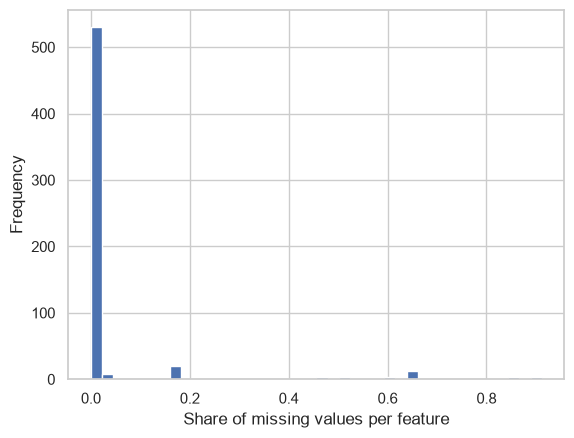

In [13]:
#| code-fold: false
def load_secom():
    """SECOM: return the process measurements X and the label y (-1 = pass, 1 = fail).

    In the UCI repository the label is not marked as target variable, so we find it
    ourselves: the only numeric column whose values are exactly -1 and 1.
    """
    df = fetch_ucirepo(id=179).data.original           # all columns of the dataset
    num = df.select_dtypes("number")                   # numeric columns only
    labels = [c for c in num.columns if set(num[c].dropna().unique()) == {-1, 1}]
    if len(labels) != 1:                               # fallback: look at the column names
        labels = [c for c in df.columns if any(k in str(c).lower() for k in ("pass", "fail", "label"))]
    assert len(labels) == 1, f"Label column not found unambiguously: {labels}"
    y = df[labels[0]].astype(int)                      # the label
    X = num.drop(columns=labels, errors="ignore")      # all other numeric columns: measurements
    print(f"Label column: {labels[0]!r}, measurement columns: {X.shape[1]}, "
          f"ignored non-numeric columns: {[c for c in df.columns if c not in num.columns]}")
    return X, y

X, y = load_secom()
missing = X.isna().mean().sort_values(ascending=False)   # share of missing values per feature
print(f"Runs: {len(X)}, failed runs: {(y == 1).sum()}")
print(f"Features: {X.shape[1]}, with any missing value: {(missing > 0).sum()}, "
      f"more than 50 % missing: {(missing > 0.5).sum()}")
missing.plot.hist(bins=40, xlabel="Share of missing values per feature")   # how are the shares distributed?
plt.show()

The label is a categorical – more precisely, a binary – variable. As explained in @sec-distributions, it is described by the frequencies of its two categories:

class
pass    1463
fail     104
Share of failed runs: 6.6%


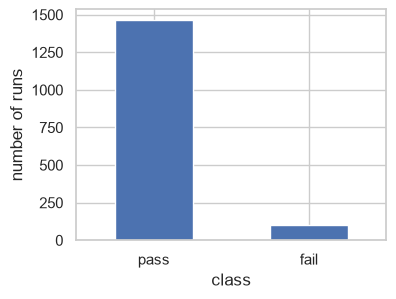

In [14]:
#| code-fold: false
label = y.map({-1: "pass", 1: "fail"})        # readable category names instead of codes
counts = label.value_counts()                 # frequency of each category
print(counts.to_string())
print(f"Share of failed runs: {counts['fail'] / counts.sum():.1%}")
fig, ax = plt.subplots(figsize=(4, 3))        # a small figure of its own
counts.plot.bar(ax=ax, rot=0, ylabel="number of runs")   # bar chart; rot=0: horizontal labels
plt.show()

Only about one run in fifteen failed. For the decision, this share matters more than the number of sensors: a model can only learn what a failure looks like from the failed runs, and rare events are hard to learn from (Chapter 7).

In [15]:
# Is the missingness itself related to the outcome?
miss_rate = X.isna().mean(axis=1)                  # axis=1: share of missing values per run (row)
print(miss_rate.groupby(y).describe().round(3))    # compare passed (-1) and failed (1) runs

# Constant features carry no information
n_constant = (X.nunique(dropna=True) <= 1).sum()   # at most one different value (gaps ignored)
print("Constant features:", n_constant)

        count   mean    std    min    25%    50%    75%    max
class                                                         
-1     1463.0  0.046  0.023  0.007  0.034  0.041  0.054  0.258
 1      104.0  0.043  0.017  0.014  0.034  0.041  0.047  0.108
Constant features: 116


**Discussion.** Most features are complete or nearly complete, but a group of features has a large share of missing values – often entire sensors that were only recorded for part of the runs. In addition, a considerable number of features are constant and can be removed without loss. Comparing the share of missing values between passed and failed runs is a quick check of whether missingness could be informative: if the shares differ, the gaps are not MCAR. Here they are similar – no sign that the gaps carry information about the outcome, although this does not prove MCAR.

A pragmatic preparation for SECOM, which we will use in Chapter 9:

1. remove constant features,
2. remove features with more than 50 % missing values,
3. impute the remaining gaps with the median,
4. standardise all features.

::: {.callout-warning}
## Pitfall: preprocessing before splitting
As soon as a model is trained, the median for imputation must be computed on the **training data only** and then applied unchanged to all new data – otherwise information from the test data leaks into the model. Chapter 6 explains why, and how a scikit-learn `Pipeline` takes care of it.
:::

### Extension: MNAR in more depth {#sec-mnar-extension}

**Censored values.** In case 3 we do not know how hot the furnace was – but we do know that it was *above 900 °C*. Such a value is called **censored**: it is not completely unknown, only bounded on one side. Censored values are everyday business in reliability engineering. A life test ends after 1,000 hours, and the parts that are still running at that point have a lifetime of "more than 1,000 hours" – missing *because* it is long. Methods for such data, e.g. a Weibull analysis with censoring, use exactly this partial information instead of discarding it. MNAR is therefore hardest when the mechanism is *unknown*.

**MAR or MNAR depends on what is measured.** The three mechanisms are defined relative to the variables in the dataset – not to everything one could have measured. In case 2, the logged load explains the gaps. If the load had not been logged, exactly the same logger behaviour would be MNAR: the gaps would depend on a quantity that is not in the data. Two practical consequences follow:

- A variable that explains the gaps only helps if it is *used*. A plain mean of the remaining temperatures is biased under MAR just as under MNAR.
- It pays to log quantities that might explain *why* values are missing – operating mode, load, sensor status. They turn an MNAR problem, which the data cannot solve, into an MAR problem, which they can.

Whether gaps are MAR or MNAR cannot be tested with the data themselves, because the missing values are unknown. It remains an assumption that has to be justified with knowledge of the process.

## Back to the decision

In CRISP-DM terms, this is the step back from phase 2 to phase 1: what we learned about the data decides whether and how the project continues. For a go/no-go recommendation, three questions matter: Are enough features usable? Are there enough examples of the event we want to predict? And are the gaps understood? We use simple, transparent criteria: at least half of the features should be non-constant with at most 50 % missing values, and there should be at least 50 failed runs to learn from.

In [16]:
#| code-fold: false
# A feature is usable if it is not constant and has at most 50 % missing values.
usable = (X.nunique(dropna=True) > 1) & (X.isna().mean() <= 0.5)
n_fail = int((y == 1).sum())                       # number of failed runs
print(f"Usable features: {usable.sum()} of {X.shape[1]} ({usable.mean():.0%})")
print(f"Failed runs: {n_fail} of {len(y)} ({n_fail / len(y):.1%})")
if usable.mean() >= 0.5 and n_fail >= 50:          # the two criteria from the text
    print("Decision: GO – with a data-quality work package in the first project phase.")
else:
    print("Decision: NO-GO for now – improve data acquisition first.")

Usable features: 446 of 590 (76%)
Failed runs: 104 of 1567 (6.6%)
Decision: GO – with a data-quality work package in the first project phase.


Whatever the code prints, the recommendation should name the conditions: the sensor names are anonymised, so no process engineer can yet judge which signals are physically relevant; the missing values must be explained (are they MAR or MNAR?); and roughly one hundred failures is a small number for a problem with hundreds of candidate features. Chapter 9 will show how hard the prediction actually is. These conditions are at the same time the tasks for the next round of the CRISP-DM cycle: with better-understood data, phases 2 and 3 are passed through again.

::: {.callout-tip}
## EDA toolbox
The functions used most in this chapter – all of them, with examples, in the Python quick reference (@sec-python-reference):

- **overview:** `df.info()`, `df.describe()`, `df.head()`, `df.nunique()`
- **missing values:** `df.isna().sum()`, `df.fillna(...)`, `pd.read_csv(..., na_values=...)`
- **time stamps:** `pd.to_datetime(..., format=...)`, `df.set_index(...)`, `s.resample(...)`, `s.rolling(...)`, `s.tz_localize(...)`, `s.tz_convert(...)`
- **groups and summaries:** `df.groupby(...).mean()`, `s.median()`, `s.quantile(...)`
- **masks and selection:** `df[m]`, `&`, `|`, `~`, `np.where(m, a, b)`
- **plots:** `sns.histplot`, `sns.boxplot`, `sns.heatmap`
:::

::: {.callout-important}
## Key takeaways
- Read raw files deliberately: separator, missing value code, time format, units and time zone are documented in the metadata.
- Describe distributions by location, spread and shape; compare classical (mean, s) and robust (median, IQR, MAD) statistics.
- Check data quality systematically: missing values, gaps in time, implausible values, frozen sensors, outliers.
- Outlier rules flag candidates – domain knowledge decides whether they are errors or important events.
- The treatment of missing data depends on the mechanism (MCAR, MAR, MNAR) – and whether gaps are MAR or MNAR depends on what else is measured.
:::

## Exercises

<div class="exercises">

1. Change the DWD code to load a weather station near your home town. The [station list](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/hourly/air_temperature/recent/TU_Stundenwerte_Beschreibung_Stationen.txt) `TU_Stundenwerte_Beschreibung_Stationen.txt` is in the same [DWD folder](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/hourly/air_temperature/recent/) as the data files.
2. Determine type and role (see Chapter 1) of each column of the raw DWD file (`STATIONS_ID`, `MESS_DATUM`, `QN_9`, `TT_TU`, `RF_TU`, `eor`) for the question "How does the air temperature in Trier vary over the day?".
3. Compute the mean temperature per hour of the day for the DWD data and plot the daily cycle. At which hour is it warmest – and does the result change if you convert the time stamps from UTC to German local time?
4. Resample the energy data to hourly values. Which aggregation (mean, sum, max, last) is correct for `Appliances`, which for the temperatures? Explain.
5. Show that the random variables `rv1` and `rv2` carry no information about `Appliances`. Compare their correlation with that of the outdoor temperature.
6. Compare the IQR rule and the robust z-score for `Appliances` after a log transformation, `np.log(energy["Appliances"])`. How many values are flagged now? What does this tell you about the "outliers" in the original scale?
7. Check all temperature columns (`T1`–`T9`, `T_out`) and humidity columns (`RH_1`–`RH_9`, `RH_out`) of the energy dataset for physically implausible values and for "frozen" periods, i.e. more than 6 identical consecutive values.
8. For SECOM: propose a strategy for features with 0–5 %, 5–50 % and more than 50 % missing values, and implement steps 1–3 of the preparation described above. How many features remain?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1
Open the station list in a browser or read it with pandas, find your station and replace `05100` in the file name. The file name of the `recent` product always has the form `stundenwerte_TU_<ID>_akt.zip`, where `<ID>` is the five-digit station ID with leading zeros. Not all stations measure all variables – if the file does not exist, choose a neighbouring station.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2
- `STATIONS_ID`: categorical (nominal) – a code, although stored as a number; constant within the file.
- `MESS_DATUM`: time stamp – numeric (differences are durations); after conversion, the index of the time series.
- `QN_9`: categorical – a code for the quality level of the record. Whether the levels are ordered must be looked up in the DWD documentation; computing a mean is meaningless either way.
- `TT_TU`: continuous (°C) – the variable of interest for this question; there is no target, because nothing is predicted.
- `RF_TU`: continuous (%) – not needed for this question.
- `eor`: not a variable at all – a marker for "end of record" in each line of the file.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

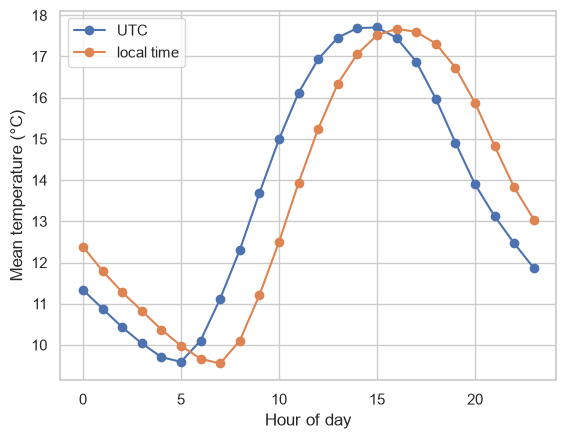

UTC           15
local time    16
dtype: int32

In [17]:
#| code-fold: false
# The DWD time stamps are in UTC: declare this (tz_localize), then convert to German time.
local = weather.tz_localize("UTC").tz_convert("Europe/Berlin")
cycle = pd.DataFrame({                                    # mean temperature per hour of day
    "UTC": weather.groupby(weather.index.hour)["temp_C"].mean(),
    "local time": local.groupby(local.index.hour)["temp_C"].mean(),
})
ax = cycle.plot(marker="o")
ax.set(xlabel="Hour of day", ylabel="Mean temperature (°C)")
plt.show()
cycle.idxmax()                                            # hour of the maximum

The maximum typically occurs in the early or mid afternoon. In local time the curve is shifted by one hour in winter and two hours in summer, so the hour of the maximum changes accordingly. This is exactly the kind of shift that causes errors when weather data are merged with production data recorded in local time.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [18]:
#| code-fold: false
# One aggregation per column: energies are summed, temperatures are averaged.
hourly = energy.resample("h").agg({"Appliances": "sum", "lights": "sum",
                                   "T1": "mean", "T_out": "mean"})
hourly.head()

,Appliances,lights,T1,T_out
date,,,,
2016-01-11 17:00:00,330,210,19.890000,6.308333
2016-01-11 18:00:00,1060,310,19.897778,5.941667
2016-01-11 19:00:00,1040,150,20.495556,6.000000
2016-01-11 20:00:00,750,210,20.961111,6.000000
2016-01-11 21:00:00,620,140,21.311667,5.833333


`Appliances` is an energy per interval (Wh in 10 minutes). The energy of one hour is the **sum** of the six 10-minute values (unit: Wh per hour, i.e. the mean power in W). Temperatures are state variables: the hourly value is the **mean** (or, for an instantaneous value, the last one). Summing temperatures would be physically meaningless. `max` is useful for questions about peaks, e.g. dimensioning a fuse.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

In [19]:
#| code-fold: false
# Correlation of each listed column with the appliance energy use
energy[["rv1", "rv2", "T_out", "T2", "RH_out"]].corrwith(energy["Appliances"]).round(3)

rv1      -0.011
rv2      -0.011
T_out     0.099
T2        0.120
RH_out   -0.152
dtype: float64

The correlations of `rv1` and `rv2` with `Appliances` are close to zero. (Check also with `energy["rv1"].equals(energy["rv2"])` whether the two random columns are identical copies – a nice example of a redundant feature.) The weather variables show small but non-zero correlations. Note that with almost 20,000 observations even tiny correlations can be "statistically significant" (Chapter 4) – the size of the correlation matters more than its p-value.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 6

In [20]:
#| code-fold: false
log_app = np.log(energy["Appliances"])             # log transformation (all values are positive)
print(f"IQR rule:          {iqr_outliers(log_app).mean():.1%}")
print(f"|robust z| > 3.5:  {(robust_z(log_app).abs() > 3.5).mean():.1%}")

IQR rule:          6.5%
|robust z| > 3.5:  7.4%


After the log transformation far fewer values are flagged. Many "outliers" on the original scale were simply the long right tail of a skewed distribution. Outlier rules implicitly assume a roughly symmetric distribution – applying them to skewed data without transformation flags normal behaviour.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 7

In [21]:
#| code-fold: false
temp_cols = [f"T{i}" for i in range(1, 10)] + ["T_out"]      # T1 ... T9 and T_out
rh_cols = [f"RH_{i}" for i in range(1, 10)] + ["RH_out"]     # RH_1 ... RH_9 and RH_out
# physical plausibility: overall temperature range, humidity outside 0–100 %
print("Temperature range (°C):", energy[temp_cols].min().min(), "to", energy[temp_cols].max().max())
print("Humidity outside 0–100 %:", ((energy[rh_cols] < 0) | (energy[rh_cols] > 100)).sum().sum())

def longest_constant_run(x):
    """Length of the longest run of identical consecutive values."""
    runs = (x != x.shift()).cumsum()     # new run number whenever the value changes
    return x.groupby(runs).size().max()  # longest run

frozen = {c: longest_constant_run(energy[c]) for c in temp_cols + rh_cols}
pd.Series(frozen).sort_values(ascending=False).head()          # the five longest runs

Temperature range (°C): -6.065 to 29.85666667
Humidity outside 0–100 %: 0


RH_6    353
T9       79
T7       78
T5       62
RH_8     42
dtype: int64

The temperature and humidity ranges should be physically plausible. Runs of identical values occur in practice because sensors report with limited resolution and indoor conditions change slowly; a run is suspicious only if it is long compared with the normal dynamics (e.g. several hours for an outdoor temperature). Here, the outdoor weather comes from an airport station with lower update rate and was interpolated to 10 minutes – this explains smooth or repeated values in the `_out` columns.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 8

In [22]:
#| code-fold: false
X1 = X.loc[:, X.nunique(dropna=True) > 1]              # 1. drop constant features
X2 = X1.loc[:, X1.isna().mean() <= 0.5]                # 2. drop > 50 % missing
X3 = X2.fillna(X2.median())                            # 3. median imputation
print(f"{X.shape[1]} -> {X1.shape[1]} (constant removed) -> {X2.shape[1]} (sparse removed)")
print("Remaining missing values:", X3.isna().sum().sum())

590 -> 474 (constant removed) -> 446 (sparse removed)
Remaining missing values: 0


Strategy: 0–5 % missing → median imputation (little influence on results); 5–50 % → median or model-based imputation plus an indicator variable "was missing"; more than 50 % → remove the feature, unless domain experts know that it is important (then investigate why it is missing). In a real project the imputation would be fitted on the training data only (see the warning above).
:::